# Citizen Assist AI: energia na enchente
## Soluções em Energias Renováveis e Sustentáveis

Em maio de 2024, Porto Alegre ficou vários dias sem luz por causa da enchente. Pensamos em uma casa onde mora uma pessoa que usa concentrador de oxigênio, que precisa de energia 24 h, e que guarda insulina na geladeira.

Nossa pergunta foi: para manter só o essencial funcionando durante **7 dias sem luz**, o que é melhor?
1. um gerador a gasolina;
2. um sistema solar com bateria (renovável).

Comparamos as duas alternativas para a mesma necessidade e o mesmo período, olhando custo, viabilidade e impacto ambiental. No final, salvamos os resultados para o assistente (`assistente.py`) usar.

Os valores marcados como "estimado" não foram medidos por nós. As fontes estão em `REFERENCIAS.md`.

### Bibliotecas
Usamos estas bibliotecas:
- `pandas`: para trabalhar com tabelas;
- `numpy`: para contas com números;
- `matplotlib`: para os gráficos;
- `LinearRegression` (scikit-learn): para a regressão linear;
- `os`, `math` e `json`: para mexer com arquivos, arredondar para cima e salvar os resultados.

In [1]:
import os
import math
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# pasta onde salvamos os gráficos e o resultados.json
os.makedirs("resultados", exist_ok=True)


# valor em reais no formato brasileiro: 1234.5 -> "R$ 1.234,50"
# (o Python escreve 1,234.50, então trocamos a vírgula e o ponto de lugar)
def formatar_reais(valor):
    texto = f"{valor:,.2f}"
    texto = texto.replace(",", "X").replace(".", ",").replace("X", ".")
    return "R$ " + texto


# mesmo formato, sem o "R$" e escolhendo as casas decimais: formatar_numero(7.27, 1) -> "7,3"
def formatar_numero(valor, casas):
    texto = f"{valor:,.{casas}f}"
    texto = texto.replace(",", "X").replace(".", ",").replace("X", ".")
    return texto

### Premissas
Juntamos aqui todos os valores fixos que usamos nas contas. Assim fica fácil conferir e trocar.

In [2]:
# período
DIAS_SEM_LUZ = 7
INICIO_SIMULACAO = "2024-05-04"   # início da falta de luz em Porto Alegre
INICIO_ENCHENTE = "2024-04-29"    # usado só no gráfico do sol
FIM_ENCHENTE = "2024-05-31"       # usado só no gráfico do sol

# gerador
POTENCIA_GERADOR_KW = 2.5         # estimado
PRECO_GERADOR = 3000.00           # R$, estimado
PRECO_GASOLINA = 6.30             # R$ por litro, ANP
CO2_POR_LITRO = 1.62              # kg de CO2 por litro de gasolina C, IPCC/MCTI

# solar + bateria (todos estimados)
RENDIMENTO_SOLAR = 0.75           # perdas de calor, sujeira, cabos e inversor
EFICIENCIA_BATERIA = 0.9
POTENCIA_PAINEL_W = 550
PRECO_SOLAR_POR_W = 4.50          # R$ por watt instalado
PRECO_BATERIA_KWH = 2800.00       # R$ por kWh de bateria

# conta de luz
TARIFA_KWH = 0.95                 # R$ por kWh, ANEEL

---
## 1. Consumo e demanda

Primeiro separamos dois conceitos:
- potência (W ou kW): é o quanto o aparelho puxa naquele instante;
- consumo (kWh): é a energia gasta ao longo do tempo, ou seja, potência × horas.

Para cada aparelho, calculamos:

$$kWh\ por\ dia = \frac{potência\ (W) \times horas\ por\ dia \times quantidade}{1000}$$

Dividimos por 1000 para passar de Wh para kWh.

In [3]:
aparelhos = pd.read_csv("dados/aparelhos.csv")

# consumo de cada aparelho por dia (kWh) e potência de cada linha (kW, usada na demanda)
aparelhos["kwh_dia"] = aparelhos["potencia_w"] * aparelhos["horas_por_dia"] * aparelhos["quantidade"] / 1000
aparelhos["potencia_total_kw"] = aparelhos["potencia_w"] * aparelhos["quantidade"] / 1000

aparelhos

,aparelho,potencia_w,horas_por_dia,quantidade,essencial,fonte,tipo_dado,kwh_dia,potencia_total_kw
0,concentrador de oxigênio,320,24.0,1,sim,manual de concentrador doméstico de 5 L/min (f...,estimado,7.680,0.320
1,geladeira,39,24.0,1,sim,selo Procel/Inmetro (~28 kWh/mês ÷ 30 dias ÷ 2...,estimado,0.936,0.039
2,lâmpada LED,9,5.0,4,sim,embalagem de lâmpada LED comum (Inmetro),estimado,0.180,0.036
3,carregador de celular,10,2.0,3,sim,etiqueta de carregador comum,estimado,0.060,0.030
4,TV,50,4.0,1,nao,etiqueta Inmetro de TV LED 32 polegadas,estimado,0.200,0.050
5,chuveiro elétrico,5500,0.5,1,nao,etiqueta de chuveiro elétrico 220 V (Inmetro),estimado,2.750,5.500


### Consumo total e consumo só dos essenciais
Na enchente, a ideia é desligar o que não é essencial: a TV e o chuveiro elétrico.

In [4]:
consumo_total = aparelhos["kwh_dia"].sum()

# só as linhas em que a coluna "essencial" é "sim"
essenciais = aparelhos[aparelhos["essencial"] == "sim"]
consumo_essencial = essenciais["kwh_dia"].sum()

economia_porcento = (consumo_total - consumo_essencial) / consumo_total * 100

print(f"Consumo com tudo ligado:   {consumo_total:.2f} kWh/dia")
print(f"Consumo só dos essenciais: {consumo_essencial:.2f} kWh/dia")
print(f"Economia:                  {economia_porcento:.1f} %")
print(f"Consumo essencial em {DIAS_SEM_LUZ} dias: {consumo_essencial * DIAS_SEM_LUZ:.2f} kWh")

Consumo com tudo ligado:   11.81 kWh/dia
Consumo só dos essenciais: 8.86 kWh/dia
Economia:                  25.0 %
Consumo essencial em 7 dias: 61.99 kWh


### Demanda máxima
Demanda é a potência necessária se todos os aparelhos ligarem ao mesmo tempo, ou seja, a soma das potências em kW. É ela que mostra se um gerador de 2,5 kW aguenta a casa.

Resumindo: o consumo (kWh) diz quanto combustível o gerador gasta, e a demanda (kW) diz se ele aguenta.

In [5]:
# soma das potências com e sem o chuveiro
demanda_com_chuveiro = aparelhos["potencia_total_kw"].sum()

sem_chuveiro = aparelhos[aparelhos["aparelho"] != "chuveiro elétrico"]
demanda_sem_chuveiro = sem_chuveiro["potencia_total_kw"].sum()

print(f"Demanda máxima COM chuveiro: {demanda_com_chuveiro:.2f} kW")
print(f"Demanda máxima SEM chuveiro: {demanda_sem_chuveiro:.2f} kW")
print(f"Gerador disponível:          {POTENCIA_GERADOR_KW:.2f} kW")
print()

if demanda_com_chuveiro > POTENCIA_GERADOR_KW:
    print("COM chuveiro: o gerador NÃO aguenta (sobrecarga).")
else:
    print("COM chuveiro: o gerador aguenta.")

if demanda_sem_chuveiro > POTENCIA_GERADOR_KW:
    print("SEM chuveiro: o gerador NÃO aguenta.")
else:
    print("SEM chuveiro: o gerador aguenta. Conclusão: NUNCA ligar o chuveiro no gerador.")

Demanda máxima COM chuveiro: 5.97 kW
Demanda máxima SEM chuveiro: 0.47 kW
Gerador disponível:          2.50 kW

COM chuveiro: o gerador NÃO aguenta (sobrecarga).
SEM chuveiro: o gerador aguenta. Conclusão: NUNCA ligar o chuveiro no gerador.


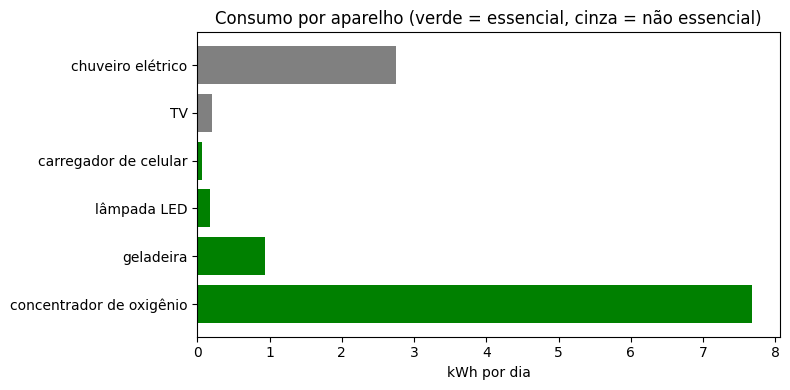

In [6]:
# barras verdes para os aparelhos essenciais e cinzas para os outros
cores = []
for valor in aparelhos["essencial"]:
    if valor == "sim":
        cores.append("green")
    else:
        cores.append("gray")

plt.figure(figsize=(8, 4))
plt.barh(aparelhos["aparelho"], aparelhos["kwh_dia"], color=cores)
plt.xlabel("kWh por dia")
plt.title("Consumo por aparelho (verde = essencial, cinza = não essencial)")
plt.tight_layout()
plt.savefig("resultados/grafico_consumo.png")
plt.show()

O gráfico mostra que o concentrador de oxigênio é, de longe, o maior consumo essencial, porque fica ligado 24 horas. O chuveiro gasta bastante, mas não é essencial na emergência.

---
## 2. Sol durante a enchente (dados reais do INMET)

Usamos os dados horários de 2024 da estação Porto Alegre (A801) do INMET. A coluna `RADIACAO GLOBAL (Kj/m²)` mostra quanta energia do sol chegou em 1 m² naquela hora.

Somamos as horas de cada dia e dividimos por 3600, porque 1 kWh = 3600 kJ. Assim temos kWh/m² por dia. Esse número é igual às horas de sol pleno (HSP): quantas horas de "sol forte" (1000 W/m²) aquele dia valeu.

Se o arquivo não estiver na pasta `dados/inmet/`, a próxima célula explica como baixar.

In [7]:
# procura o CSV da estação A801 na pasta; se não achar, explica como baixar
pasta_inmet = "dados/inmet"
arquivo_inmet = ""

for nome in os.listdir(pasta_inmet):
    if nome.upper().endswith(".CSV") and "A801" in nome.upper():
        arquivo_inmet = os.path.join(pasta_inmet, nome)

if arquivo_inmet == "":
    print("ARQUIVO DO INMET NÃO ENCONTRADO!")
    print("1. Acesse https://portal.inmet.gov.br/dadoshistoricos")
    print("2. Baixe o arquivo do ano 2024 (é um .zip)")
    print("3. Dentro do zip, pegue o arquivo com 'A801' e 'PORTO ALEGRE' no nome")
    print("4. Coloque esse arquivo na pasta dados/inmet/ e rode o notebook de novo")
    raise FileNotFoundError("Falta o CSV do INMET em dados/inmet/ (veja as instruções acima).")

print("Arquivo encontrado:", arquivo_inmet)

Arquivo encontrado: dados/inmet\INMET_S_RS_A801_PORTO ALEGRE - JARDIM BOTANICO_01-01-2024_A_31-12-2024.CSV


In [8]:
# o CSV do INMET tem 8 linhas de informações antes da tabela,
# usa ";" entre as colunas, "," como decimal e acentos em latin-1
inmet = pd.read_csv(arquivo_inmet, skiprows=8, sep=";", decimal=",", encoding="latin-1")

coluna_data = inmet.columns[0]

# a coluna da radiação é a que tem "RADIACAO" no nome
coluna_radiacao = ""
for coluna in inmet.columns:
    if "RADIACAO" in coluna.upper():
        coluna_radiacao = coluna

print("Coluna de data:", coluna_data)
print("Coluna de radiação:", coluna_radiacao)
inmet[[coluna_data, "Hora UTC", coluna_radiacao]].head(15)

Coluna de data: Data
Coluna de radiação: RADIACAO GLOBAL (Kj/m²)


,Data,Hora UTC,RADIACAO GLOBAL (Kj/m²)
0,2024/01/01,0000 UTC,NaN
1,2024/01/01,0100 UTC,NaN
2,2024/01/01,0200 UTC,NaN
3,2024/01/01,0300 UTC,NaN
4,2024/01/01,0400 UTC,NaN
5,2024/01/01,0500 UTC,NaN
6,2024/01/01,0600 UTC,NaN
7,2024/01/01,0700 UTC,NaN
8,2024/01/01,0800 UTC,NaN
9,2024/01/01,0900 UTC,26.5


### Limpeza dos dados
- Quando o sensor não mede, o INMET coloca -9999. Trocamos por "sem dado" (`NaN`).
- À noite às vezes aparecem valores negativos pequenos. Trocamos por 0.
- Um dia com menos de 8 horas medidas fica incompleto, porque a soma sairia baixa demais. Por isso ele não entra nas médias.

In [9]:
inmet["data"] = pd.to_datetime(inmet[coluna_data])
inmet["radiacao"] = pd.to_numeric(inmet[coluna_radiacao], errors="coerce")

# -9999 vira "sem dado" e os negativos da noite viram 0
inmet.loc[inmet["radiacao"] == -9999, "radiacao"] = np.nan
inmet.loc[inmet["radiacao"] < 0, "radiacao"] = 0

# soma da radiação de cada dia (kJ/m²) e quantas horas tiveram medição
diario = pd.DataFrame()
diario["radiacao_kj"] = inmet.groupby("data")["radiacao"].sum()
diario["horas_com_dado"] = inmet.groupby("data")["radiacao"].count()

# kJ/m² para kWh/m²: esse valor é a HSP do dia
diario["hsp"] = diario["radiacao_kj"] / 3600

# tira os dias incompletos
dias_antes = len(diario)
diario = diario[diario["horas_com_dado"] >= 8]
print(f"Dias no arquivo: {dias_antes} | dias completos usados: {len(diario)}")
diario.head()

Dias no arquivo: 366 | dias completos usados: 366


,radiacao_kj,horas_com_dado,hsp
data,,,
2024-01-01,23556.8,14,6.543556
2024-01-02,15142.5,15,4.206250
2024-01-03,21468.4,15,5.963444
2024-01-04,24387.5,15,6.774306
2024-01-05,29323.1,15,8.145306


In [10]:
hsp_media_ano = diario["hsp"].mean()

maio = diario[diario.index.month == 5]
hsp_media_maio = maio["hsp"].mean()

diferenca_maio = (hsp_media_maio - hsp_media_ano) / hsp_media_ano * 100

print(f"HSP média do ano de 2024: {hsp_media_ano:.2f} kWh/m² por dia")
print(f"HSP média de maio/2024:   {hsp_media_maio:.2f} kWh/m² por dia ({len(maio)} dias com dado)")
print(f"Maio teve {diferenca_maio:+.1f} % de sol em relação à média do ano")

HSP média do ano de 2024: 4.07 kWh/m² por dia
HSP média de maio/2024:   1.94 kWh/m² por dia (31 dias com dado)
Maio teve -52.4 % de sol em relação à média do ano


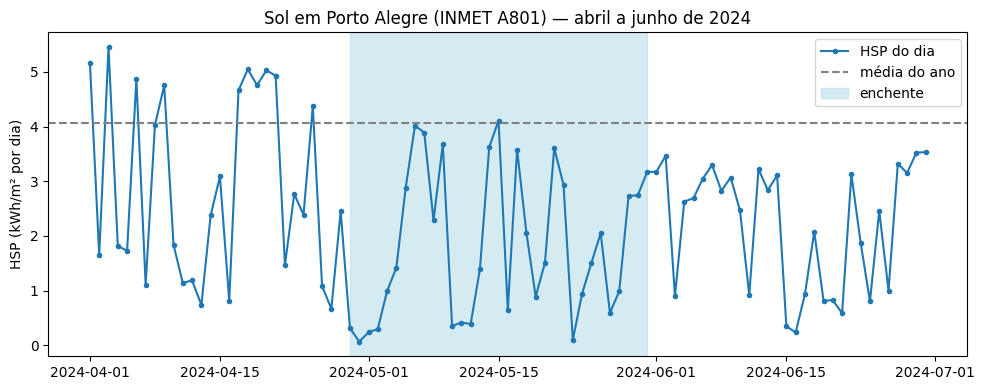

In [11]:
# HSP de cada dia de abril a junho, com a faixa da enchente e a média do ano
abr_jun = diario[(diario.index >= "2024-04-01") & (diario.index <= "2024-06-30")]

plt.figure(figsize=(10, 4))
plt.plot(abr_jun.index, abr_jun["hsp"], marker="o", markersize=3, label="HSP do dia")
plt.axhline(hsp_media_ano, color="gray", linestyle="--", label="média do ano")
plt.axvspan(pd.to_datetime(INICIO_ENCHENTE), pd.to_datetime(FIM_ENCHENTE),
            color="lightblue", alpha=0.5, label="enchente")
plt.ylabel("HSP (kWh/m² por dia)")
plt.title("Sol em Porto Alegre (INMET A801) — abril a junho de 2024")
plt.legend()
plt.tight_layout()
plt.savefig("resultados/grafico_sol.png")
plt.show()

Cada ponto é um dia e a faixa azul é o período da enchente. Percebemos que os dias de chuva e céu fechado têm HSP baixa, e são justamente os dias em que a luz falta. Os pontos que "somem" são dias sem medição completa.

---
## 3. Gerador: regressão linear (scikit-learn)

O consumo de gasolina de um gerador depende da carga: quanto mais aparelhos ligados, mais gasolina. O manual do fabricante costuma informar o consumo em algumas cargas. Com esses pontos, treinamos uma regressão linear para achar a reta:

$$consumo\ (L/h) = a \times carga\ (kW) + b$$

Atenção: os dados de `gerador_manual.csv` são de **exemplo**. Eles devem ser trocados pelos dados do manual de um gerador real.

In [12]:
gerador = pd.read_csv("dados/gerador_manual.csv")

# X é a entrada (carga) e y é o que queremos prever (consumo).
# X tem dois colchetes porque o scikit-learn espera uma tabela.
X = gerador[["carga_kw"]]
y = gerador["consumo_l_h"]

modelo = LinearRegression()
modelo.fit(X, y)

# a = inclinação da reta, b = onde ela corta o eixo y,
# R² = quanto mais perto de 1, melhor a reta explica os pontos
a = modelo.coef_[0]
b = modelo.intercept_
r2 = modelo.score(X, y)

print(f"Equação: consumo (L/h) = {a:.3f} × carga (kW) + {b:.3f}")
print(f"R² = {r2:.3f}")

Equação: consumo (L/h) = 0.464 × carga (kW) + 0.225
R² = 0.999


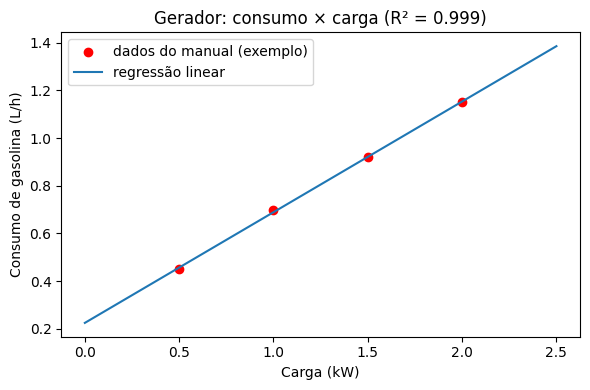

In [13]:
# pontos do manual e a reta da regressão, de 0 até 2,5 kW
cargas = np.linspace(0, POTENCIA_GERADOR_KW, 50)
reta = a * cargas + b

plt.figure(figsize=(6, 4))
plt.scatter(gerador["carga_kw"], gerador["consumo_l_h"], color="red", label="dados do manual (exemplo)")
plt.plot(cargas, reta, label="regressão linear")
plt.xlabel("Carga (kW)")
plt.ylabel("Consumo de gasolina (L/h)")
plt.title(f"Gerador: consumo × carga (R² = {r2:.3f})")
plt.legend()
plt.tight_layout()
plt.savefig("resultados/grafico_gerador.png")
plt.show()

### Quanto o gerador gasta na nossa casa?
A carga média da casa é o consumo essencial dividido por 24 horas (kWh ÷ h = kW). Colocamos essa carga na equação da reta para prever os litros por hora.

In [14]:
# carga média da casa colocada na equação da reta
carga_media_kw = consumo_essencial / 24
consumo_gerador_l_h = a * carga_media_kw + b

horas = 24 * DIAS_SEM_LUZ
litros_gerador = consumo_gerador_l_h * horas
custo_gerador_7d = litros_gerador * PRECO_GASOLINA
co2_gerador = litros_gerador * CO2_POR_LITRO

print(f"Carga média da casa: {carga_media_kw:.3f} kW")
if carga_media_kw < gerador["carga_kw"].min():
    print("Atenção: essa carga é menor que o menor ponto do manual. A previsão é uma extrapolação.")
print(f"Consumo previsto: {consumo_gerador_l_h:.3f} L/h")
print()
print(f"Em {DIAS_SEM_LUZ} dias ({horas} horas):")
print(f"  Gasolina: {litros_gerador:.1f} litros")
print(f"  Custo:    {formatar_reais(custo_gerador_7d)}")
print(f"  CO2:      {co2_gerador:.1f} kg")

Carga média da casa: 0.369 kW
Atenção: essa carga é menor que o menor ponto do manual. A previsão é uma extrapolação.
Consumo previsto: 0.396 L/h

Em 7 dias (168 horas):
  Gasolina: 66.6 litros
  Custo:    R$ 419,36
  CO2:      107.8 kg


---
## 4. Solar + bateria

### Dimensionamento
Usamos estas fórmulas:
- potência dos painéis (kWp) = consumo diário ÷ (HSP média do ano × rendimento 0,75);
- número de painéis = kWp ÷ 0,55 kW, arredondado para cima, porque não existe meio painel;
- bateria (kWh) = consumo diário ÷ 0,9. Ela guarda 1 dia de consumo essencial.

Um sistema solar comum (on-grid), sem bateria, desliga sozinho quando a luz da rua cai. Isso é uma proteção obrigatória, para não dar choque em quem está consertando a rede. Por isso escolhemos um sistema com bateria.

In [15]:
kwp_necessario = consumo_essencial / (hsp_media_ano * RENDIMENTO_SOLAR)
numero_paineis = math.ceil(kwp_necessario * 1000 / POTENCIA_PAINEL_W)
kwp_instalado = numero_paineis * POTENCIA_PAINEL_W / 1000

# a bateria útil é a parte que realmente usamos (90%)
bateria_kwh = consumo_essencial / EFICIENCIA_BATERIA
bateria_util_kwh = bateria_kwh * EFICIENCIA_BATERIA

custo_paineis = kwp_instalado * 1000 * PRECO_SOLAR_POR_W
custo_bateria = bateria_kwh * PRECO_BATERIA_KWH
investimento_solar = custo_paineis + custo_bateria

print(f"Potência necessária: {kwp_necessario:.2f} kWp")
print(f"Painéis de {POTENCIA_PAINEL_W} W: {numero_paineis} painéis = {kwp_instalado:.2f} kWp instalados")
print(f"Bateria: {bateria_kwh:.2f} kWh")
print()
print(f"Custo dos painéis: {formatar_reais(custo_paineis)}")
print(f"Custo da bateria:  {formatar_reais(custo_bateria)}")
print(f"Investimento total: {formatar_reais(investimento_solar)}")

Potência necessária: 2.90 kWp
Painéis de 550 W: 6 painéis = 3.30 kWp instalados
Bateria: 9.84 kWh

Custo dos painéis: R$ 14.850,00
Custo da bateria:  R$ 27.552,00
Investimento total: R$ 42.402,00


### Simulação dos 7 dias da enchente com o sol real de cada dia
Colocamos a simulação dentro da função `simular_semana(data_inicio)`. Ela devolve a tabela dia a dia e a % atendida, e assim conseguimos simular qualquer semana (seção 4b).

Para cada dia, com um `for`:
1. geração do dia = kWp × HSP real do dia × 0,75;
2. se gerou mais do que o consumo, a sobra carrega a bateria (até encher);
3. se gerou menos, a falta sai da bateria;
4. se a bateria acabar, o resto vira energia que faltou.

A bateria começa cheia, porque estava carregada antes de a luz cair. Se o INMET não tiver dado de algum dia, usamos HSP = 0 (pior caso) e mostramos um aviso.

In [16]:
# simula 7 dias a partir de data_inicio e devolve a tabela dia a dia e a % atendida
def simular_semana(data_inicio):
    datas = pd.date_range(data_inicio, periods=DIAS_SEM_LUZ)

    carga_bateria = bateria_util_kwh   # a bateria começa cheia
    linhas = []

    for data in datas:
        if data in diario.index:
            hsp_dia = diario.loc[data, "hsp"]
        else:
            hsp_dia = 0
            print(f"Aviso: sem dado do INMET em {data.date()}. Usando HSP = 0 (pior caso).")

        geracao = kwp_instalado * hsp_dia * RENDIMENTO_SOLAR
        faltou = 0

        if geracao >= consumo_essencial:
            # sobrou energia: carrega a bateria, sem passar de cheia
            sobra = geracao - consumo_essencial
            carga_bateria = carga_bateria + sobra
            if carga_bateria > bateria_util_kwh:
                carga_bateria = bateria_util_kwh
        else:
            # faltou energia: usa a bateria, e o que ela não cobrir vira "faltou"
            falta = consumo_essencial - geracao
            if carga_bateria >= falta:
                carga_bateria = carga_bateria - falta
            else:
                faltou = falta - carga_bateria
                carga_bateria = 0

        linhas.append({
            "dia": str(data.date()),
            "hsp": round(float(hsp_dia), 2),
            "geracao_kwh": round(float(geracao), 2),
            "consumo_kwh": round(float(consumo_essencial), 2),
            "bateria_fim_do_dia_kwh": round(float(carga_bateria), 2),
            "faltou_kwh": round(float(faltou), 2),
        })

    tabela = pd.DataFrame(linhas)

    energia_necessaria = consumo_essencial * DIAS_SEM_LUZ
    energia_faltou = tabela["faltou_kwh"].sum()
    porcentagem = (energia_necessaria - energia_faltou) / energia_necessaria * 100

    return tabela, porcentagem


# semana principal: começa em 04/05
simulacao, porcentagem_atendida_solar = simular_semana(INICIO_SIMULACAO)
simulacao

,dia,hsp,geracao_kwh,consumo_kwh,bateria_fim_do_dia_kwh,faltou_kwh
0,2024-05-04,1.42,3.52,8.86,3.52,0.00
1,2024-05-05,2.88,7.13,8.86,1.79,0.00
2,2024-05-06,4.02,9.95,8.86,2.88,0.00
3,2024-05-07,3.89,9.63,8.86,3.66,0.00
4,2024-05-08,2.29,5.66,8.86,0.46,0.00
5,2024-05-09,3.68,9.10,8.86,0.70,0.00
6,2024-05-10,0.36,0.88,8.86,0.00,7.27


In [17]:
energia_necessaria = consumo_essencial * DIAS_SEM_LUZ
energia_faltou = simulacao["faltou_kwh"].sum()
dias_com_falta = len(simulacao[simulacao["faltou_kwh"] > 0])

print(f"Energia necessária em {DIAS_SEM_LUZ} dias: {energia_necessaria:.2f} kWh")
print(f"Energia que faltou: {energia_faltou:.2f} kWh ({dias_com_falta} dia(s) com falta)")
print(f"Necessidade atendida pelo solar + bateria: {porcentagem_atendida_solar:.1f} %")

Energia necessária em 7 dias: 61.99 kWh
Energia que faltou: 7.27 kWh (1 dia(s) com falta)
Necessidade atendida pelo solar + bateria: 88.3 %


---
## 4b. E se fosse outra semana?
A semana de 04/05 é só uma das semanas da enchente. Para ver se o resultado muda muito, simulamos uma semana começando em cada dia de 27/04 até 25/05/2024. O sistema é sempre o mesmo (mesmos painéis e mesma bateria) e o sol é o real de cada dia. Isso se chama análise de sensibilidade.

In [18]:
# uma simulação para cada data de início, de 27/04 até 25/05/2024
datas_inicio = pd.date_range("2024-04-27", "2024-05-25")

linhas_semanas = []
for data_inicio in datas_inicio:
    tabela_semana, porcentagem_semana = simular_semana(data_inicio)
    linhas_semanas.append({
        "inicio": str(data_inicio.date()),
        "atendida_%": round(float(porcentagem_semana), 1),
    })

semanas = pd.DataFrame(linhas_semanas)
semanas

,inicio,atendida_%
0,2024-04-27,34.4
1,2024-04-28,37.4
2,2024-04-29,39.1
3,2024-04-30,52.1
4,2024-05-01,66.1
5,2024-05-02,77.3
6,2024-05-03,90.4
7,2024-05-04,88.3
8,2024-05-05,84.0
9,2024-05-06,71.3


In [19]:
# idxmin e idxmax dão a linha com o menor e com o maior valor
indice_pior = semanas["atendida_%"].idxmin()
indice_melhor = semanas["atendida_%"].idxmax()

pior_semana_inicio = semanas.loc[indice_pior, "inicio"]
pior_semana_porcento = semanas.loc[indice_pior, "atendida_%"]
melhor_semana_inicio = semanas.loc[indice_melhor, "inicio"]
melhor_semana_porcento = semanas.loc[indice_melhor, "atendida_%"]
media_semanas_porcento = semanas["atendida_%"].mean()

print(f"PIOR semana:   começa em {pior_semana_inicio} -> {pior_semana_porcento:.1f} % atendido")
print(f"MELHOR semana: começa em {melhor_semana_inicio} -> {melhor_semana_porcento:.1f} % atendido")
print(f"Média das {len(semanas)} semanas: {media_semanas_porcento:.1f} %")
print(f"Semana principal ({INICIO_SIMULACAO}): {porcentagem_atendida_solar:.1f} %")

PIOR semana:   começa em 2024-04-27 -> 34.4 % atendido
MELHOR semana: começa em 2024-05-03 -> 90.4 % atendido
Média das 29 semanas: 65.5 %
Semana principal (2024-05-04): 88.3 %


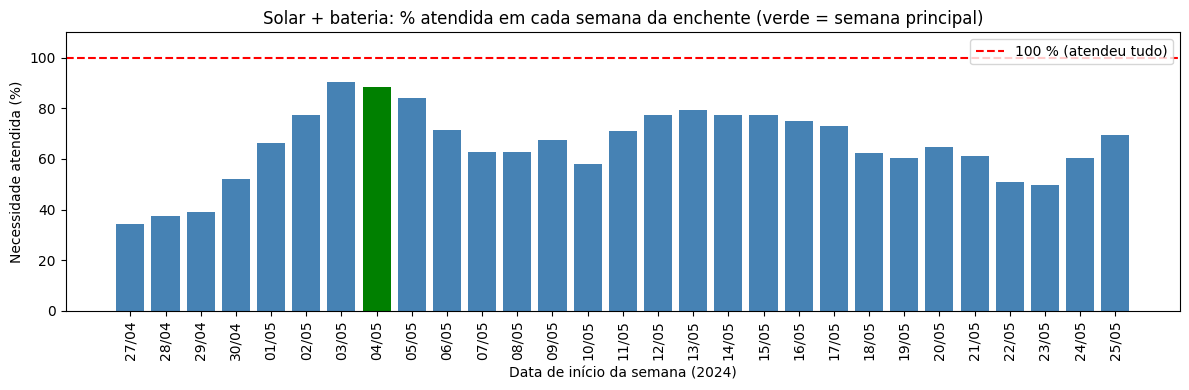

In [20]:
# barra verde para a semana principal (04/05) e azul para as outras
cores_semanas = []
rotulos = []
for inicio in semanas["inicio"]:
    if inicio == INICIO_SIMULACAO:
        cores_semanas.append("green")
    else:
        cores_semanas.append("steelblue")
    rotulos.append(inicio[8:10] + "/" + inicio[5:7])   # "2024-05-04" vira "04/05"

plt.figure(figsize=(12, 4))
plt.bar(rotulos, semanas["atendida_%"], color=cores_semanas)
plt.axhline(100, color="red", linestyle="--", label="100 % (atendeu tudo)")
plt.xticks(rotation=90)
plt.xlabel("Data de início da semana (2024)")
plt.ylabel("Necessidade atendida (%)")
plt.title("Solar + bateria: % atendida em cada semana da enchente (verde = semana principal)")
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.savefig("resultados/grafico_semanas.png")
plt.show()

Percebemos que, com a mesma instalação, o resultado muda muito de uma semana para outra. A bateria guarda só 1 dia de consumo, então o que decide o resultado é quantos dias seguidos de chuva acontecem:
- com 1 dia nublado, a bateria segura e recarrega no próximo dia de sol;
- com vários dias nublados seguidos, a bateria esvazia no 1º dia e o painel não gera o suficiente para recarregar. Aí falta energia.

No início da enchente, no fim de abril e começo de maio, choveu vários dias seguidos. É ali que ficam as piores semanas. Para uma pessoa que depende de oxigênio, não dá para contar só com a média: precisamos planejar para a **pior** semana.

---
## 5. Comparação final
Comparamos as duas alternativas para a mesma necessidade (aparelhos essenciais) e o mesmo período (7 dias sem luz).

- O gerador atende 100% se houver gasolina. Na enchente, porém, postos fecharam e ruas ficaram alagadas.
- O solar não gasta combustível nem emite CO2 durante o uso, mas depende do sol.

In [21]:
comparacao = pd.DataFrame({
    "alternativa": ["Gerador a gasolina", "Solar + bateria"],
    "investimento_r$": [PRECO_GERADOR, investimento_solar],
    "custo_7_dias_r$": [custo_gerador_7d, 0],
    "litros_7_dias": [litros_gerador, 0],
    "co2_kg_7_dias": [co2_gerador, 0],
    "atendida_%": [100, porcentagem_atendida_solar],
    "depende_de": ["gasolina (postos podem fechar)", "sol (dias nublados)"],
})
comparacao.round(1)

,alternativa,investimento_r$,custo_7_dias_r$,litros_7_dias,co2_kg_7_dias,atendida_%,depende_de
0,Gerador a gasolina,3000.0,419.4,66.6,107.8,100.0,gasolina (postos podem fechar)
1,Solar + bateria,42402.0,0.0,0.0,0.0,88.3,sol (dias nublados)


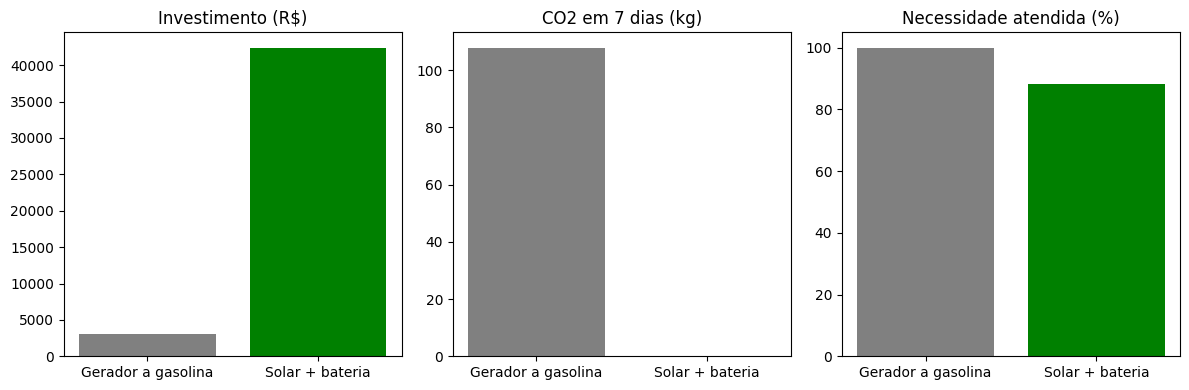

In [22]:
# 3 gráficos lado a lado: investimento, CO2 e % atendida
nomes = comparacao["alternativa"]
cores = ["gray", "green"]

fig, eixos = plt.subplots(1, 3, figsize=(12, 4))

eixos[0].bar(nomes, comparacao["investimento_r$"], color=cores)
eixos[0].set_title("Investimento (R$)")

eixos[1].bar(nomes, comparacao["co2_kg_7_dias"], color=cores)
eixos[1].set_title("CO2 em 7 dias (kg)")

eixos[2].bar(nomes, comparacao["atendida_%"], color=cores)
eixos[2].set_title("Necessidade atendida (%)")
eixos[2].set_ylim(0, 105)

plt.tight_layout()
plt.savefig("resultados/grafico_comparacao.png")
plt.show()

### E fora da enchente?
O solar continua gerando o ano todo e diminui a conta de luz. Com isso, calculamos em quantos anos ele se paga.

In [23]:
geracao_anual_kwh = kwp_instalado * hsp_media_ano * RENDIMENTO_SOLAR * 365
economia_anual = geracao_anual_kwh * TARIFA_KWH

anos_paga_total = investimento_solar / economia_anual
anos_paga_paineis = custo_paineis / economia_anual

print(f"Geração por ano: {geracao_anual_kwh:.0f} kWh")
print(f"Economia na conta: {formatar_reais(economia_anual)} por ano")
print(f"Sistema completo (painéis + bateria) se paga em: {anos_paga_total:.1f} anos")
print(f"Só os painéis se pagariam em: {anos_paga_paineis:.1f} anos")

Geração por ano: 3678 kWh
Economia na conta: R$ 3.494,46 por ano
Sistema completo (painéis + bateria) se paga em: 12.1 anos
Só os painéis se pagariam em: 4.2 anos


---
## 6. Recomendação
A recomendação é escolhida pelo código, a partir dos números que calculamos acima.

In [24]:
# quanto o gerador de reserva teria que cobrir na semana principal (04/05)
horas_gerador_reserva = energia_faltou / carga_media_kw
litros_hibrido = horas_gerador_reserva * consumo_gerador_l_h

# e na pior semana, que é a semana para a qual precisamos planejar (seção 4b)
tabela_pior, porcentagem_pior = simular_semana(pior_semana_inicio)
energia_faltou_pior = tabela_pior["faltou_kwh"].sum()
litros_hibrido_pior = (energia_faltou_pior / carga_media_kw) * consumo_gerador_l_h

# datas no formato dd/mm para o texto: "2024-04-27" vira "27/04"
data_principal = INICIO_SIMULACAO[8:10] + "/" + INICIO_SIMULACAO[5:7]
data_pior = pior_semana_inicio[8:10] + "/" + pior_semana_inicio[5:7]

# o solar sozinho só é recomendado se atender quase tudo até na pior semana
if pior_semana_porcento >= 99:
    recomendacao = (f"Solar + bateria atendeu pelo menos {formatar_numero(pior_semana_porcento, 0)}% da necessidade "
                    f"em todas as semanas da enchente, sem gasolina e sem CO2 no uso. É a melhor opção se houver "
                    f"dinheiro para investir. Mesmo assim, ter cilindro de oxigênio de reserva.")
else:
    recomendacao = (f"Solar + bateria atendeu {formatar_numero(porcentagem_atendida_solar, 0)}% da necessidade "
                    f"na semana de {data_principal}, mas, dependendo da semana, o solar atendeu de "
                    f"{formatar_numero(pior_semana_porcento, 0)}% a {formatar_numero(melhor_semana_porcento, 0)}% "
                    f"(média de {formatar_numero(media_semanas_porcento, 0)}%), porque houve vários dias seguidos de "
                    f"pouco sol. O ideal é um sistema HÍBRIDO: solar + bateria e um gerador de reserva "
                    f"(sempre fora de casa) para os dias de pouco sol. "
                    f"Na semana de {data_principal} o gerador de reserva cobriria "
                    f"{formatar_numero(energia_faltou, 1)} kWh (cerca de {formatar_numero(litros_hibrido, 1)} L de gasolina); "
                    f"na pior semana ({data_pior}) cobriria {formatar_numero(energia_faltou_pior, 1)} kWh "
                    f"(cerca de {formatar_numero(litros_hibrido_pior, 1)} L), contra "
                    f"{formatar_numero(litros_gerador, 1)} L usando só o gerador. "
                    f"Como a pessoa depende de oxigênio, o gerador de reserva e o cilindro de oxigênio são "
                    f"obrigatórios mesmo com o solar. Se não houver dinheiro para o solar, o gerador sozinho "
                    f"atende, desde que haja gasolina guardada com segurança.")

print(recomendacao)

Solar + bateria atendeu 88% da necessidade na semana de 04/05, mas, dependendo da semana, o solar atendeu de 34% a 90% (média de 66%), porque houve vários dias seguidos de pouco sol. O ideal é um sistema HÍBRIDO: solar + bateria e um gerador de reserva (sempre fora de casa) para os dias de pouco sol. Na semana de 04/05 o gerador de reserva cobriria 7,3 kWh (cerca de 7,8 L de gasolina); na pior semana (27/04) cobriria 40,7 kWh (cerca de 43,7 L), contra 66,6 L usando só o gerador. Como a pessoa depende de oxigênio, o gerador de reserva e o cilindro de oxigênio são obrigatórios mesmo com o solar. Se não houver dinheiro para o solar, o gerador sozinho atende, desde que haja gasolina guardada com segurança.


### Limitações
Estes pontos podem deixar os nossos números diferentes da realidade:
- Consumo: as potências vêm de etiquetas e manuais típicos, nós não medimos. A geladeira usa a média (39 W), mas ao ligar o compressor puxa bem mais por alguns segundos.
- Gerador: os dados de consumo são de exemplo. A carga da casa (cerca de 0,37 kW) fica abaixo do menor ponto do manual, então a previsão é uma extrapolação. Não consideramos troca de óleo, manutenção nem a dificuldade de comprar gasolina na enchente.
- Solar: usamos um rendimento fixo de 0,75. Painéis sujos, com sombra ou em área alagada geram menos. Na simulação, a bateria começa cheia.
- INMET: usamos os dados de uma estação só (A801). Descartamos os dias com menos de 8 horas medidas. A soma por dia usa o horário UTC (3 h de diferença), o que quase não muda nada, porque essas horas são de noite.
- Semana escolhida: o resultado do solar depende da semana escolhida (ver seção 4b).
- CO2: no solar, contamos só o uso. A fabricação dos painéis e da bateria também emite.
- Economia anual: usamos a tarifa cheia, sem as regras da geração distribuída (Lei 14.300/2022), que diminuem um pouco a economia.
- Preços: mudam com o tempo e a região. É preciso conferir antes de decidir.
- Saúde: este trabalho não substitui orientação médica nem da Defesa Civil.

---
## 7. Salvar os resultados para o assistente
O `assistente.py` lê este arquivo. Assim, os números do assistente são os mesmos do notebook.

In [25]:
# lista de aparelhos com números normais do Python, para o json conseguir salvar
lista_aparelhos = []
for indice, linha in aparelhos.iterrows():
    lista_aparelhos.append({
        "aparelho": linha["aparelho"],
        "potencia_w": float(linha["potencia_w"]),
        "horas_por_dia": float(linha["horas_por_dia"]),
        "quantidade": int(linha["quantidade"]),
        "kwh_dia": round(float(linha["kwh_dia"]), 3),
        "essencial": linha["essencial"],
        "tipo_dado": linha["tipo_dado"],
    })

resultados = {
    "dias_sem_luz": DIAS_SEM_LUZ,
    "consumo": {
        "total_kwh_dia": round(float(consumo_total), 2),
        "essencial_kwh_dia": round(float(consumo_essencial), 2),
        "economia_porcento": round(float(economia_porcento), 1),
        "aparelhos": lista_aparelhos,
    },
    "demanda": {
        "com_chuveiro_kw": round(float(demanda_com_chuveiro), 2),
        "sem_chuveiro_kw": round(float(demanda_sem_chuveiro), 2),
        "potencia_gerador_kw": POTENCIA_GERADOR_KW,
    },
    "inmet": {
        "hsp_media_ano": round(float(hsp_media_ano), 2),
        "hsp_media_maio": round(float(hsp_media_maio), 2),
        "diferenca_maio_porcento": round(float(diferenca_maio), 1),
    },
    "gerador": {
        "equacao_a": round(float(a), 4),
        "equacao_b": round(float(b), 4),
        "r2": round(float(r2), 4),
        "carga_media_kw": round(float(carga_media_kw), 3),
        "consumo_l_h": round(float(consumo_gerador_l_h), 3),
        "litros_7_dias": round(float(litros_gerador), 1),
        "custo_7_dias": round(float(custo_gerador_7d), 2),
        "co2_kg_7_dias": round(float(co2_gerador), 1),
        "investimento": PRECO_GERADOR,
        "atendida_porcento": 100,
    },
    "solar": {
        "kwp_instalado": round(float(kwp_instalado), 2),
        "numero_paineis": int(numero_paineis),
        "bateria_kwh": round(float(bateria_kwh), 2),
        "investimento": round(float(investimento_solar), 2),
        "atendida_porcento": round(float(porcentagem_atendida_solar), 1),
        "energia_faltou_kwh": round(float(energia_faltou), 2),
        "simulacao": simulacao.to_dict("records"),
        "economia_anual": round(float(economia_anual), 2),
        "anos_para_se_pagar": round(float(anos_paga_total), 1),
        # seção 4b: todas as semanas da enchente
        "pior_semana_inicio": pior_semana_inicio,
        "pior_semana_porcento": round(float(pior_semana_porcento), 1),
        "melhor_semana_porcento": round(float(melhor_semana_porcento), 1),
        "media_semanas_porcento": round(float(media_semanas_porcento), 1),
        # gerador de reserva do híbrido na pior semana
        "energia_faltou_pior": round(float(energia_faltou_pior), 2),
        "litros_hibrido_pior": round(float(litros_hibrido_pior), 1),
    },
    "recomendacao": recomendacao,
    "premissas": {
        "preco_gasolina": PRECO_GASOLINA,
        "co2_por_litro": CO2_POR_LITRO,
        "tarifa_kwh": TARIFA_KWH,
        "preco_solar_por_w": PRECO_SOLAR_POR_W,
        "preco_bateria_kwh": PRECO_BATERIA_KWH,
    },
}

with open("resultados/resultados.json", "w", encoding="utf-8") as arquivo:
    json.dump(resultados, arquivo, ensure_ascii=False, indent=2)

print("Resultados salvos em resultados/resultados.json")

Resultados salvos em resultados/resultados.json
